In [1]:
import os
import re  
import math
import pickle
import zipfile
from collections import defaultdict

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d import Axes3D  

import h5py
from scipy import signal
from scipy.stats import (zscore, ks_2samp, linregress, pearsonr)
from scipy.signal import (convolve, windows, resample)
from scipy.ndimage import gaussian_filter1d

from sklearn.preprocessing import (PolynomialFeatures, StandardScaler)
from sklearn.model_selection import (train_test_split, cross_val_score, KFold,GridSearchCV)


from scipy.signal import convolve, windows
from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from pyglmnet import GLM


from sklearn.linear_model import PoissonRegressor
from sklearn.pipeline import make_pipeline
from scipy.interpolate import interp1d


In [2]:
session_files1 = {
    "Day01": [
        'E3_MB01_Day01High_1.pkl', 'E3_MB01_Day01High_11.pkl', 'E3_MB01_Day01High_14.pkl',
        'E3_MB01_Day01High_17.pkl', 'E3_MB01_Day01High_21.pkl', 'E3_MB01_Day01High_24.pkl',
        'E3_MB01_Day01High_27.pkl', 'E3_MB01_Day01High_30.pkl', 'E3_MB01_Day01High_6.pkl',
        'E3_MB01_Day01High_9.pkl'
    ],
    "Day03": [
        'E3_MB01_Day03High_11.pkl', 'E3_MB01_Day03High_14.pkl', 'E3_MB01_Day03High_18.pkl',
        'E3_MB01_Day03High_21.pkl', 'E3_MB01_Day03High_23.pkl', 'E3_MB01_Day03High_26.pkl',
        'E3_MB01_Day03High_29.pkl', 'E3_MB01_Day03High_3.pkl', 'E3_MB01_Day03High_4.pkl',
        'E3_MB01_Day03High_9.pkl'
    ],
    "Day04": [
        'E3_MB01_Day04High_1.pkl', 'E3_MB01_Day04High_10.pkl', 'E3_MB01_Day04High_13.pkl',
        'E3_MB01_Day04High_17.pkl', 'E3_MB01_Day04High_20.pkl', 'E3_MB01_Day04High_23.pkl',
        'E3_MB01_Day04High_25.pkl', 'E3_MB01_Day04High_29.pkl', 'E3_MB01_Day04High_30.pkl',
        'E3_MB01_Day04High_6.pkl', 'E3_MB01_Day04High_9.pkl'
    ],
    "Day05": [
        'E3_MB01_Day05High_1.pkl', 'E3_MB01_Day05High_10.pkl', 'E3_MB01_Day05High_13.pkl',
        'E3_MB01_Day05High_18.pkl', 'E3_MB01_Day05High_21.pkl', 'E3_MB01_Day05High_23.pkl',
        'E3_MB01_Day05High_26.pkl', 'E3_MB01_Day05High_28.pkl', 'E3_MB01_Day05High_5.pkl',
        'E3_MB01_Day05High_9.pkl'
    ],
    "Day06": [
        'E3_MB01_Day06High_10.pkl', 'E3_MB01_Day06High_14.pkl', 'E3_MB01_Day06High_18.pkl',
        'E3_MB01_Day06High_21.pkl', 'E3_MB01_Day06High_22.pkl', 'E3_MB01_Day06High_26.pkl',
        'E3_MB01_Day06High_3.pkl', 'E3_MB01_Day06High_30.pkl', 'E3_MB01_Day06High_5.pkl',
        'E3_MB01_Day06High_9.pkl'
    ],
    "Day07": [
        'E3_MB01_Day07High_1.pkl', 'E3_MB01_Day07High_10.pkl', 'E3_MB01_Day07High_14.pkl',
        'E3_MB01_Day07High_18.pkl', 'E3_MB01_Day07High_19.pkl', 'E3_MB01_Day07High_23.pkl',
        'E3_MB01_Day07High_26.pkl', 'E3_MB01_Day07High_28.pkl', 'E3_MB01_Day07High_5.pkl',
        'E3_MB01_Day07High_9.pkl'
        
    ],
    
    "Day08": ['E3_MB01_Day08High_12.pkl', 'E3_MB01_Day08High_13.pkl', 'E3_MB01_Day08High_17.pkl',
              'E3_MB01_Day08High_21.pkl', 'E3_MB01_Day08High_23.pkl', 'E3_MB01_Day08High_25.pkl',
              'E3_MB01_Day08High_3.pkl', 'E3_MB01_Day08High_30.pkl', 'E3_MB01_Day08High_7.pkl'],
    "Day09": ['E3_MB01_Day09High_1.pkl', 'E3_MB01_Day09High_13.pkl', 'E3_MB01_Day09High_15.pkl',
              'E3_MB01_Day09High_18.pkl', 'E3_MB01_Day09High_23.pkl', 'E3_MB01_Day09High_26.pkl',
              'E3_MB01_Day09High_27.pkl', 'E3_MB01_Day09High_4.pkl', 'E3_MB01_Day09High_8.pkl',
              'E3_MB01_Day09High_9.pkl'],
    "Day10": ['E3_MB01_Day10High_1.pkl', 'E3_MB01_Day10High_10.pkl', 'E3_MB01_Day10High_15.pkl',
              'E3_MB01_Day10High_18.pkl', 'E3_MB01_Day10High_19.pkl', 'E3_MB01_Day10High_22.pkl',
              'E3_MB01_Day10High_25.pkl', 'E3_MB01_Day10High_30.pkl', 'E3_MB01_Day10High_5.pkl',
              'E3_MB01_Day10High_7.pkl'],
    "Day11": ['E3_MB01_Day11High_12.pkl', 'E3_MB01_Day11High_15.pkl', 'E3_MB01_Day11High_18.pkl',
              'E3_MB01_Day11High_20.pkl', 'E3_MB01_Day11High_24.pkl', 'E3_MB01_Day11High_25.pkl',
              'E3_MB01_Day11High_28.pkl', 'E3_MB01_Day11High_3.pkl', 'E3_MB01_Day11High_4.pkl',
              'E3_MB01_Day11High_8.pkl'],
    "Day12": ['E3_MB01_Day12High_12.pkl', 'E3_MB01_Day12High_15.pkl', 'E3_MB01_Day12High_17.pkl',
              'E3_MB01_Day12High_2.pkl', 'E3_MB01_Day12High_20.pkl', 'E3_MB01_Day12High_24.pkl',
              'E3_MB01_Day12High_25.pkl', 'E3_MB01_Day12High_28.pkl', 'E3_MB01_Day12High_4.pkl',
              'E3_MB01_Day12High_7.pkl'],
    "Day13": ['E3_MB01_Day13High_1.pkl', 'E3_MB01_Day13High_12.pkl', 'E3_MB01_Day13High_14.pkl',
              'E3_MB01_Day13High_16.pkl', 'E3_MB01_Day13High_19.pkl', 'E3_MB01_Day13High_23.pkl',
              'E3_MB01_Day13High_25.pkl', 'E3_MB01_Day13High_30.pkl', 'E3_MB01_Day13High_5.pkl',
              'E3_MB01_Day13High_9.pkl'],
    "Day14": ['E3_MB01_Day14High_12.pkl', 'E3_MB01_Day14High_15.pkl', 'E3_MB01_Day14High_18.pkl',
              'E3_MB01_Day14High_19.pkl', 'E3_MB01_Day14High_22.pkl', 'E3_MB01_Day14High_26.pkl',
              'E3_MB01_Day14High_28.pkl', 'E3_MB01_Day14High_3.pkl', 'E3_MB01_Day14High_5.pkl',
              'E3_MB01_Day14High_8.pkl']

}



#######################





session_files3 = {
    "Day01": ['E3_MB03_Day01High_12.pkl', 'E3_MB03_Day01High_14.pkl', 'E3_MB03_Day01High_16.pkl',
              'E3_MB03_Day01High_19.pkl', 'E3_MB03_Day01High_23.pkl', 'E3_MB03_Day01High_27.pkl',
              'E3_MB03_Day01High_29.pkl', 'E3_MB03_Day01High_3.pkl', 'E3_MB03_Day01High_4.pkl',
              'E3_MB03_Day01High_8.pkl'],
    "Day02": ['E3_MB03_Day02High_12.pkl', 'E3_MB03_Day02High_15.pkl', 'E3_MB03_Day02High_17.pkl',
              'E3_MB03_Day02High_19.pkl', 'E3_MB03_Day02High_2.pkl', 'E3_MB03_Day02High_24.pkl',
              'E3_MB03_Day02High_26.pkl', 'E3_MB03_Day02High_29.pkl', 'E3_MB03_Day02High_6.pkl',
              'E3_MB03_Day02High_8.pkl'],
    "Day03": ['E3_MB03_Day03High_10.pkl', 'E3_MB03_Day03High_15.pkl', 'E3_MB03_Day03High_17.pkl',
              'E3_MB03_Day03High_2.pkl', 'E3_MB03_Day03High_21.pkl', 'E3_MB03_Day03High_23.pkl',
              'E3_MB03_Day03High_26.pkl', 'E3_MB03_Day03High_29.pkl', 'E3_MB03_Day03High_5.pkl',
              'E3_MB03_Day03High_9.pkl'],
    "Day04": ['E3_MB03_Day04High_1.pkl', 'E3_MB03_Day04High_11.pkl', 'E3_MB03_Day04High_15.pkl',
              'E3_MB03_Day04High_16.pkl', 'E3_MB03_Day04High_20.pkl', 'E3_MB03_Day04High_23.pkl',
              'E3_MB03_Day04High_26.pkl', 'E3_MB03_Day04High_28.pkl', 'E3_MB03_Day04High_4.pkl',
              'E3_MB03_Day04High_9.pkl'],
    "Day05": ['E3_MB03_Day05High_12.pkl', 'E3_MB03_Day05High_15.pkl', 'E3_MB03_Day05High_17.pkl',
              'E3_MB03_Day05High_20.pkl', 'E3_MB03_Day05High_22.pkl', 'E3_MB03_Day05High_26.pkl',
              'E3_MB03_Day05High_29.pkl', 'E3_MB03_Day05High_3.pkl', 'E3_MB03_Day05High_4.pkl',
              'E3_MB03_Day05High_7.pkl'],
    "Day07": ['E3_MB03_Day07High_11.pkl', 'E3_MB03_Day07High_13.pkl', 'E3_MB03_Day07High_18.pkl',
              'E3_MB03_Day07High_19.pkl', 'E3_MB03_Day07High_22.pkl', 'E3_MB03_Day07High_27.pkl',
              'E3_MB03_Day07High_29.pkl', 'E3_MB03_Day07High_3.pkl', 'E3_MB03_Day07High_7.pkl'],
    "Day10": ['E3_MB03_Day10High_12.pkl', 'E3_MB03_Day10High_13.pkl', 'E3_MB03_Day10High_17.pkl',
              'E3_MB03_Day10High_21.pkl', 'E3_MB03_Day10High_22.pkl', 'E3_MB03_Day10High_25.pkl',
              'E3_MB03_Day10High_3.pkl', 'E3_MB03_Day10High_30.pkl', 'E3_MB03_Day10High_5.pkl',
              'E3_MB03_Day10High_8.pkl'],
    "Day11": ['E3_MB03_Day11High_10.pkl', 'E3_MB03_Day11High_14.pkl', 'E3_MB03_Day11High_18.pkl',
              'E3_MB03_Day11High_20.pkl', 'E3_MB03_Day11High_23.pkl', 'E3_MB03_Day11High_26.pkl',
              'E3_MB03_Day11High_3.pkl', 'E3_MB03_Day11High_30.pkl', 'E3_MB03_Day11High_6.pkl',
              'E3_MB03_Day11High_9.pkl'],
    "Day12": ['E3_MB03_Day12High_12.pkl', 'E3_MB03_Day12High_13.pkl', 'E3_MB03_Day12High_17.pkl',
              'E3_MB03_Day12High_21.pkl', 'E3_MB03_Day12High_22.pkl', 'E3_MB03_Day12High_25.pkl',
              'E3_MB03_Day12High_29.pkl', 'E3_MB03_Day12High_3.pkl', 'E3_MB03_Day12High_5.pkl',
              'E3_MB03_Day12High_8.pkl'],
    "Day13": ['E3_MB03_Day13High_12.pkl', 'E3_MB03_Day13High_13.pkl', 'E3_MB03_Day13High_18.pkl',
              'E3_MB03_Day13High_19.pkl', 'E3_MB03_Day13High_2.pkl', 'E3_MB03_Day13High_24.pkl',
              'E3_MB03_Day13High_27.pkl', 'E3_MB03_Day13High_29.pkl', 'E3_MB03_Day13High_5.pkl',
              'E3_MB03_Day13High_7.pkl'],
    "Day14": ['E3_MB03_Day14High_12.pkl', 'E3_MB03_Day14High_13.pkl', 'E3_MB03_Day14High_16.pkl',
              'E3_MB03_Day14High_21.pkl', 'E3_MB03_Day14High_24.pkl', 'E3_MB03_Day14High_26.pkl',
              'E3_MB03_Day14High_29.pkl', 'E3_MB03_Day14High_3.pkl', 'E3_MB03_Day14High_4.pkl',
              'E3_MB03_Day14High_8.pkl']
}


#######################



session_files2 = {
    "Day02": [
        'E3_MB02_Day02High_10.pkl', 'E3_MB02_Day02High_14.pkl', 'E3_MB02_Day02High_18.pkl',
        'E3_MB02_Day02High_2.pkl', 'E3_MB02_Day02High_20.pkl', 'E3_MB02_Day02High_24.pkl',
        'E3_MB02_Day02High_27.pkl', 'E3_MB02_Day02High_29.pkl', 'E3_MB02_Day02High_6.pkl',
        'E3_MB02_Day02High_9.pkl'
    ],
    "Day03": [
        'E3_MB02_Day03High_11.pkl', 'E3_MB02_Day03High_13.pkl', 'E3_MB02_Day03High_18.pkl',
        'E3_MB02_Day03High_21.pkl', 'E3_MB02_Day03High_24.pkl', 'E3_MB02_Day03High_26.pkl',
        'E3_MB02_Day03High_29.pkl', 'E3_MB02_Day03High_3.pkl', 'E3_MB02_Day03High_5.pkl',
        'E3_MB02_Day03High_7.pkl'
    ],
    "Day04": [
        'E3_MB02_Day04High_11.pkl', 'E3_MB02_Day04High_14.pkl', 'E3_MB02_Day04High_16.pkl',
        'E3_MB02_Day04High_2.pkl', 'E3_MB02_Day04High_21.pkl', 'E3_MB02_Day04High_22.pkl',
        'E3_MB02_Day04High_27.pkl', 'E3_MB02_Day04High_30.pkl', 'E3_MB02_Day04High_5.pkl',
        'E3_MB02_Day04High_7.pkl'
    ],
    "Day07": [
        'E3_MB02_Day07High_1.pkl', 'E3_MB02_Day07High_12.pkl', 'E3_MB02_Day07High_13.pkl',
        'E3_MB02_Day07High_16.pkl', 'E3_MB02_Day07High_19.pkl', 'E3_MB02_Day07High_24.pkl',
        'E3_MB02_Day07High_27.pkl', 'E3_MB02_Day07High_30.pkl', 'E3_MB02_Day07High_4.pkl',
        'E3_MB02_Day07High_9.pkl'
    ],
    "Day13": [
        'E3_MB02_Day13High_1.pkl', 'E3_MB02_Day13High_11.pkl', 'E3_MB02_Day13High_13.pkl',
        'E3_MB02_Day13High_18.pkl', 'E3_MB02_Day13High_20.pkl', 'E3_MB02_Day13High_23.pkl',
        'E3_MB02_Day13High_26.pkl', 'E3_MB02_Day13High_28.pkl', 'E3_MB02_Day13High_4.pkl',
        'E3_MB02_Day13High_8.pkl'
    ]
}



#######################




session_files4 = {
    "Day01": ['E3_MB04_Day01High_16.pkl', 'E3_MB04_Day01High_19.pkl', 'E3_MB04_Day01High_2.pkl',
              'E3_MB04_Day01High_24.pkl', 'E3_MB04_Day01High_26.pkl', 'E3_MB04_Day01High_30.pkl',
              'E3_MB04_Day01High_6.pkl', 'E3_MB04_Day01High_8.pkl'],
    "Day03": ['E3_MB04_Day03High_10.pkl', 'E3_MB04_Day03High_14.pkl', 'E3_MB04_Day03High_17.pkl',
              'E3_MB04_Day03High_19.pkl', 'E3_MB04_Day03High_22.pkl', 'E3_MB04_Day03High_27.pkl',
              'E3_MB04_Day03High_28.pkl', 'E3_MB04_Day03High_3.pkl', 'E3_MB04_Day03High_5.pkl',
              'E3_MB04_Day03High_8.pkl'],
    "Day07": ['E3_MB04_Day07High_15.pkl', 'E3_MB04_Day07High_29.pkl', 'E3_MB04_Day07High_6.pkl',
              'E3_MB04_Day07High_8.pkl'],
    "Day08": ['E3_MB04_Day08High_11.pkl', 'E3_MB04_Day08High_13.pkl', 'E3_MB04_Day08High_18.pkl',
              'E3_MB04_Day08High_19.pkl', 'E3_MB04_Day08High_2.pkl', 'E3_MB04_Day08High_22.pkl',
              'E3_MB04_Day08High_27.pkl', 'E3_MB04_Day08High_28.pkl', 'E3_MB04_Day08High_6.pkl',
              'E3_MB04_Day08High_9.pkl'],
    "Day09": ['E3_MB04_Day09High_1.pkl', 'E3_MB04_Day09High_19.pkl', 'E3_MB04_Day09High_24.pkl',
              'E3_MB04_Day09High_27.pkl', 'E3_MB04_Day09High_30.pkl', 'E3_MB04_Day09High_6.pkl'],
    "Day10": ['E3_MB04_Day10High_11.pkl', 'E3_MB04_Day10High_15.pkl', 'E3_MB04_Day10High_17.pkl',
              'E3_MB04_Day10High_2.pkl', 'E3_MB04_Day10High_21.pkl', 'E3_MB04_Day10High_22.pkl',
              'E3_MB04_Day10High_26.pkl', 'E3_MB04_Day10High_28.pkl', 'E3_MB04_Day10High_4.pkl',
              'E3_MB04_Day10High_9.pkl'],
    "Day11": ['E3_MB04_Day11High_10.pkl', 'E3_MB04_Day11High_14.pkl', 'E3_MB04_Day11High_16.pkl',
              'E3_MB04_Day11High_2.pkl', 'E3_MB04_Day11High_21.pkl', 'E3_MB04_Day11High_23.pkl',
              'E3_MB04_Day11High_27.pkl', 'E3_MB04_Day11High_28.pkl', 'E3_MB04_Day11High_4.pkl',
              'E3_MB04_Day11High_9.pkl'],
    
    "Day12": ['E3_MB04_Day12High_2.pkl', 'E3_MB04_Day12High_5.pkl', 'E3_MB04_Day12High_9.pkl',
              'E3_MB04_Day12High_12.pkl', 'E3_MB04_Day12High_14.pkl', 'E3_MB04_Day12High_18.pkl',
              'E3_MB04_Day12High_19.pkl', 'E3_MB04_Day12High_23.pkl', 'E3_MB04_Day12High_26.pkl',
              'E3_MB04_Day12High_29.pkl'],
        
    "Day13": ['E3_MB04_Day13High_3.pkl', 'E3_MB04_Day13High_4.pkl', 'E3_MB04_Day13High_8.pkl',
              'E3_MB04_Day13High_12.pkl', 'E3_MB04_Day13High_14.pkl', 'E3_MB04_Day13High_18.pkl',
              'E3_MB04_Day13High_19.pkl', 'E3_MB04_Day13High_24.pkl', 'E3_MB04_Day13High_27.pkl',
              'E3_MB04_Day13High_30.pkl'],
            
    "Day14": ['E3_MB04_Day14High_3.pkl', 'E3_MB04_Day14High_4.pkl', 'E3_MB04_Day14High_8.pkl',
              'E3_MB04_Day14High_11.pkl', 'E3_MB04_Day14High_13.pkl', 'E3_MB04_Day14High_18.pkl',
              'E3_MB04_Day14High_21.pkl', 'E3_MB04_Day14High_25.pkl', 'E3_MB04_Day14High_28.pkl']
}



#######################



session_files7 = {
    "Day01": [
        'E3_MB07_Day01High_10.pkl', 'E3_MB07_Day01High_13.pkl', 'E3_MB07_Day01High_17.pkl',
        'E3_MB07_Day01High_2.pkl', 'E3_MB07_Day01High_21.pkl', 'E3_MB07_Day01High_24.pkl',
        'E3_MB07_Day01High_26.pkl', 'E3_MB07_Day01High_28.pkl', 'E3_MB07_Day01High_5.pkl',
        'E3_MB07_Day01High_9.pkl'
    ],
    "Day02": [
        'E3_MB07_Day02High_10.pkl', 'E3_MB07_Day02High_15.pkl', 'E3_MB07_Day02High_17.pkl',
        'E3_MB07_Day02High_19.pkl', 'E3_MB07_Day02High_23.pkl', 'E3_MB07_Day02High_27.pkl',
        'E3_MB07_Day02High_3.pkl', 'E3_MB07_Day02High_30.pkl', 'E3_MB07_Day02High_5.pkl',
        'E3_MB07_Day02High_9.pkl'
    ],
    "Day03": [
        'E3_MB07_Day03High_1.pkl', 'E3_MB07_Day03High_10.pkl', 'E3_MB07_Day03High_15.pkl',
        'E3_MB07_Day03High_18.pkl', 'E3_MB07_Day03High_19.pkl', 'E3_MB07_Day03High_22.pkl',
        'E3_MB07_Day03High_25.pkl', 'E3_MB07_Day03High_30.pkl', 'E3_MB07_Day03High_5.pkl',
        'E3_MB07_Day03High_7.pkl'
    ],
    "Day04": [
        'E3_MB07_Day04High_11.pkl', 'E3_MB07_Day04High_15.pkl', 'E3_MB07_Day04High_18.pkl',
        'E3_MB07_Day04High_21.pkl', 'E3_MB07_Day04High_23.pkl', 'E3_MB07_Day04High_27.pkl',
        'E3_MB07_Day04High_28.pkl', 'E3_MB07_Day04High_3.pkl', 'E3_MB07_Day04High_6.pkl',
        'E3_MB07_Day04High_7.pkl'
    ],
    "Day05": [
        'E3_MB07_Day05High_12.pkl', 'E3_MB07_Day05High_15.pkl', 'E3_MB07_Day05High_16.pkl',
        'E3_MB07_Day05High_19.pkl', 'E3_MB07_Day05High_24.pkl', 'E3_MB07_Day05High_26.pkl',
        'E3_MB07_Day05High_3.pkl', 'E3_MB07_Day05High_30.pkl', 'E3_MB07_Day05High_5.pkl',
        'E3_MB07_Day05High_7.pkl'
    ],
    "Day06": [
        'E3_MB07_Day06High_10.pkl', 'E3_MB07_Day06High_15.pkl', 'E3_MB07_Day06High_16.pkl',
        'E3_MB07_Day06High_19.pkl', 'E3_MB07_Day06High_24.pkl', 'E3_MB07_Day06High_25.pkl',
        'E3_MB07_Day06High_29.pkl', 'E3_MB07_Day06High_3.pkl', 'E3_MB07_Day06High_6.pkl',
        'E3_MB07_Day06High_8.pkl'
    ],
    "Day07": [
        'E3_MB07_Day07High_1.pkl', 'E3_MB07_Day07High_10.pkl', 'E3_MB07_Day07High_13.pkl',
        'E3_MB07_Day07High_18.pkl', 'E3_MB07_Day07High_20.pkl', 'E3_MB07_Day07High_24.pkl',
        'E3_MB07_Day07High_26.pkl', 'E3_MB07_Day07High_29.pkl', 'E3_MB07_Day07High_6.pkl',
        'E3_MB07_Day07High_9.pkl'
    ],
    "Day08": [
        'E3_MB07_Day08High_12.pkl', 'E3_MB07_Day08High_13.pkl', 'E3_MB07_Day08High_17.pkl',
        'E3_MB07_Day08High_2.pkl', 'E3_MB07_Day08High_20.pkl', 'E3_MB07_Day08High_24.pkl',
        'E3_MB07_Day08High_26.pkl', 'E3_MB07_Day08High_28.pkl', 'E3_MB07_Day08High_4.pkl',
        'E3_MB07_Day08High_9.pkl'
    ],
    "Day09": [
        'E3_MB07_Day09High_10.pkl', 'E3_MB07_Day09High_12.pkl', 'E3_MB07_Day09High_13.pkl',
        'E3_MB07_Day09High_14.pkl', 'E3_MB07_Day09High_18.pkl', 'E3_MB07_Day09High_19.pkl',
        'E3_MB07_Day09High_2.pkl', 'E3_MB07_Day09High_21.pkl', 'E3_MB07_Day09High_22.pkl',
        'E3_MB07_Day09High_23.pkl', 'E3_MB07_Day09High_25.pkl', 'E3_MB07_Day09High_28.pkl',
        'E3_MB07_Day09High_3.pkl', 'E3_MB07_Day09High_30.pkl', 'E3_MB07_Day09High_4.pkl',
        'E3_MB07_Day09High_6.pkl', 'E3_MB07_Day09High_9.pkl'
    ],
    "Day10": [
        'E3_MB07_Day10High_10.pkl', 'E3_MB07_Day10High_13.pkl', 'E3_MB07_Day10High_16.pkl',
        'E3_MB07_Day10High_2.pkl', 'E3_MB07_Day10High_21.pkl', 'E3_MB07_Day10High_22.pkl',
        'E3_MB07_Day10High_26.pkl', 'E3_MB07_Day10High_29.pkl', 'E3_MB07_Day10High_4.pkl',
        'E3_MB07_Day10High_9.pkl'
    ]
}


#######################



session_files6 = {
    "Day01": [
        'E3_MB06_Day01High_10.pkl', 'E3_MB06_Day01High_13.pkl', 'E3_MB06_Day01High_16.pkl',
        'E3_MB06_Day01High_2.pkl', 'E3_MB06_Day01High_21.pkl', 'E3_MB06_Day01High_22.pkl',
        'E3_MB06_Day01High_27.pkl', 'E3_MB06_Day01High_28.pkl', 'E3_MB06_Day01High_6.pkl',
        'E3_MB06_Day01High_7.pkl'
    ],
    "Day03": [
        'E3_MB06_Day03High_1.pkl', 'E3_MB06_Day03High_10.pkl', 'E3_MB06_Day03High_14.pkl',
        'E3_MB06_Day03High_17.pkl', 'E3_MB06_Day03High_21.pkl', 'E3_MB06_Day03High_22.pkl',
        'E3_MB06_Day03High_27.pkl', 'E3_MB06_Day03High_29.pkl', 'E3_MB06_Day03High_6.pkl',
        'E3_MB06_Day03High_8.pkl'
    ],
    "Day04": [
        'E3_MB06_Day04High_10.pkl', 'E3_MB06_Day04High_14.pkl', 'E3_MB06_Day04High_17.pkl',
        'E3_MB06_Day04High_21.pkl', 'E3_MB06_Day04High_24.pkl', 'E3_MB06_Day04High_26.pkl',
        'E3_MB06_Day04High_3.pkl', 'E3_MB06_Day04High_30.pkl', 'E3_MB06_Day04High_5.pkl',
        'E3_MB06_Day04High_9.pkl'
    ],
    "Day05": [
        'E3_MB06_Day05High_1.pkl', 'E3_MB06_Day05High_12.pkl', 'E3_MB06_Day05High_13.pkl',
        'E3_MB06_Day05High_18.pkl', 'E3_MB06_Day05High_20.pkl', 'E3_MB06_Day05High_24.pkl',
        'E3_MB06_Day05High_27.pkl', 'E3_MB06_Day05High_29.pkl', 'E3_MB06_Day05High_5.pkl',
        'E3_MB06_Day05High_8.pkl'
    ],
    "Day06": [
        'E3_MB06_Day06High_1.pkl', 'E3_MB06_Day06High_12.pkl', 'E3_MB06_Day06High_14.pkl',
        'E3_MB06_Day06High_18.pkl', 'E3_MB06_Day06High_20.pkl', 'E3_MB06_Day06High_23.pkl',
        'E3_MB06_Day06High_27.pkl', 'E3_MB06_Day06High_29.pkl', 'E3_MB06_Day06High_4.pkl',
        'E3_MB06_Day06High_9.pkl'
    ],
    "Day07": [
        'E3_MB06_Day07High_1.pkl', 'E3_MB06_Day07High_10.pkl', 'E3_MB06_Day07High_15.pkl',
        'E3_MB06_Day07High_16.pkl', 'E3_MB06_Day07High_21.pkl', 'E3_MB06_Day07High_22.pkl',
        'E3_MB06_Day07High_26.pkl', 'E3_MB06_Day07High_28.pkl', 'E3_MB06_Day07High_6.pkl',
        'E3_MB06_Day07High_9.pkl'
    ],
    "Day08": [
        'E3_MB06_Day08High_12.pkl', 'E3_MB06_Day08High_14.pkl', 'E3_MB06_Day08High_18.pkl',
        'E3_MB06_Day08High_19.pkl', 'E3_MB06_Day08High_2.pkl', 'E3_MB06_Day08High_23.pkl',
        'E3_MB06_Day08High_26.pkl', 'E3_MB06_Day08High_29.pkl', 'E3_MB06_Day08High_4.pkl',
        'E3_MB06_Day08High_8.pkl'
    ],
    "Day09": [
        'E3_MB06_Day09High_1.pkl', 'E3_MB06_Day09High_11.pkl', 'E3_MB06_Day09High_14.pkl',
        'E3_MB06_Day09High_16.pkl', 'E3_MB06_Day09High_20.pkl', 'E3_MB06_Day09High_22.pkl',
        'E3_MB06_Day09High_27.pkl', 'E3_MB06_Day09High_30.pkl', 'E3_MB06_Day09High_6.pkl',
        'E3_MB06_Day09High_8.pkl'
    ],
    "Day10": [
        'E3_MB06_Day10High_10.pkl', 'E3_MB06_Day10High_14.pkl', 'E3_MB06_Day10High_17.pkl',
        'E3_MB06_Day10High_19.pkl', 'E3_MB06_Day10High_23.pkl', 'E3_MB06_Day10High_26.pkl',
        'E3_MB06_Day10High_29.pkl', 'E3_MB06_Day10High_3.pkl', 'E3_MB06_Day10High_6.pkl',
        'E3_MB06_Day10High_9.pkl'
    ],
    "Day11": [
        'E3_MB06_Day11High_11.pkl', 'E3_MB06_Day11High_15.pkl', 'E3_MB06_Day11High_16.pkl',
        'E3_MB06_Day11High_19.pkl', 'E3_MB06_Day11High_23.pkl', 'E3_MB06_Day11High_27.pkl',
        'E3_MB06_Day11High_29.pkl', 'E3_MB06_Day11High_3.pkl', 'E3_MB06_Day11High_6.pkl',
        'E3_MB06_Day11High_9.pkl'
    ],
    "Day12": [
        'E3_MB06_Day12High_10.pkl', 'E3_MB06_Day12High_14.pkl', 'E3_MB06_Day12High_16.pkl',
        'E3_MB06_Day12High_21.pkl', 'E3_MB06_Day12High_24.pkl', 'E3_MB06_Day12High_25.pkl',
        'E3_MB06_Day12High_3.pkl', 'E3_MB06_Day12High_30.pkl', 'E3_MB06_Day12High_5.pkl',
        'E3_MB06_Day12High_9.pkl'
    ],
    "Day13": [
        'E3_MB06_Day13High_12.pkl', 'E3_MB06_Day13High_13.pkl', 'E3_MB06_Day13High_17.pkl',
        'E3_MB06_Day13High_20.pkl', 'E3_MB06_Day13High_23.pkl', 'E3_MB06_Day13High_25.pkl',
        'E3_MB06_Day13High_3.pkl', 'E3_MB06_Day13High_30.pkl', 'E3_MB06_Day13High_6.pkl',
        'E3_MB06_Day13High_8.pkl'
    ],
    "Day14": [
        'E3_MB06_Day14High_11.pkl', 'E3_MB06_Day14High_15.pkl', 'E3_MB06_Day14High_16.pkl',
        'E3_MB06_Day14High_2.pkl', 'E3_MB06_Day14High_20.pkl', 'E3_MB06_Day14High_23.pkl',
        'E3_MB06_Day14High_26.pkl', 'E3_MB06_Day14High_28.pkl', 'E3_MB06_Day14High_6.pkl',
        'E3_MB06_Day14High_9.pkl'
    ]
}


# SPIKE MODEL


=== Max firing rates for session Day01 ===
Neuron 0: 14.95 Hz
Neuron 1: 13.96 Hz
Neuron 2: 0.00 Hz
Neuron 4: 24.59 Hz
Neuron 5: 14.56 Hz
Neuron 6: 15.05 Hz
Neuron 7: 0.00 Hz
Neuron 8: 14.22 Hz
Neuron 9: 18.97 Hz
Neuron 10: 6.68 Hz
Neuron 11: 13.99 Hz
Neuron 12: 15.59 Hz
Neuron 13: 30.84 Hz

=== Max firing rates for session Day02 ===
Neuron 0: 13.33 Hz
Neuron 2: 10.43 Hz
Neuron 3: 14.96 Hz
Neuron 4: 15.07 Hz
Neuron 5: 12.94 Hz
Neuron 6: 15.61 Hz
Neuron 7: 16.04 Hz
Neuron 8: 13.71 Hz
Neuron 9: 15.78 Hz
Neuron 10: 15.09 Hz
Neuron 11: 15.29 Hz
Neuron 12: 15.05 Hz

=== Max firing rates for session Day03 ===
Neuron 0: 15.40 Hz
Neuron 1: 13.21 Hz
Neuron 2: 13.35 Hz
Neuron 3: 21.42 Hz
Neuron 4: 11.32 Hz
Neuron 5: 12.02 Hz
Neuron 6: 24.40 Hz
Neuron 7: 34.28 Hz
Neuron 8: 15.67 Hz
Neuron 9: 15.20 Hz
Neuron 10: 22.23 Hz
Neuron 11: 13.76 Hz

=== Max firing rates for session Day04 ===
Neuron 0: 15.70 Hz
Neuron 1: 12.38 Hz
Neuron 3: 10.58 Hz
Neuron 4: 13.89 Hz
Neuron 5: 18.91 Hz
Neuron 6: 10.85 Hz
N

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_47077/3060399460.py:123: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2, palette=palette_dict, cut=0)


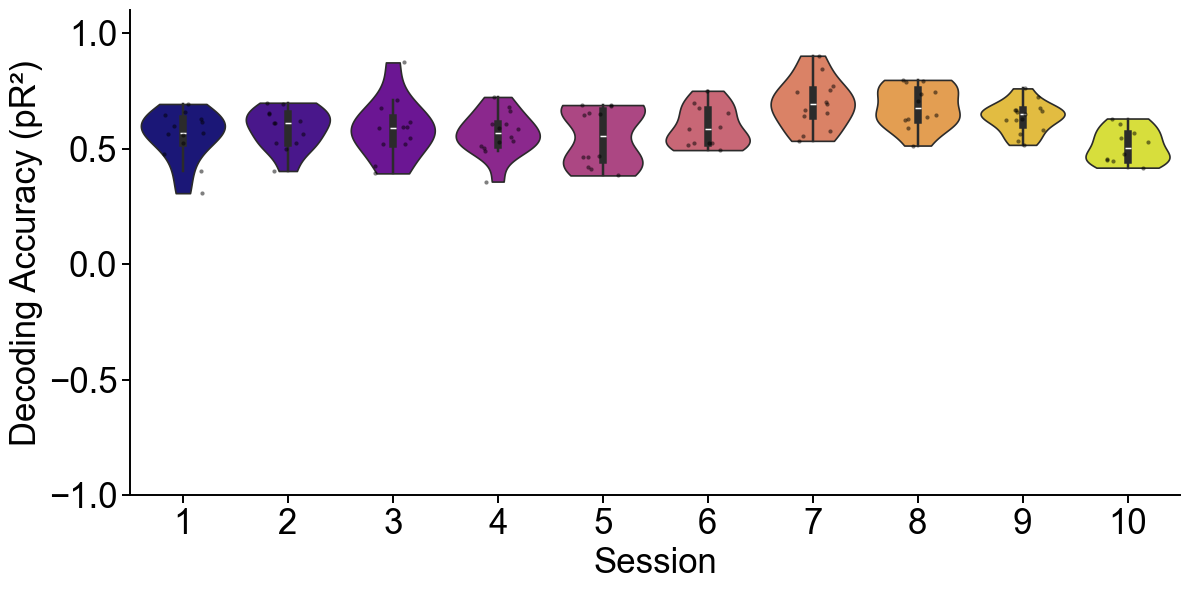

In [16]:
from functions_experimental_data_Bräckleinexp.GLM_analysis_spikes_pred import *

# === Parameters ===
folder_path = '/Users/nmt121/Desktop/DATA/S7/' #path to experimental data
session_files = session_files7 #path to the names of the files

bin_size_ms = 200 
fsamp = 2048 #fsamp exp data
window_duration = 0.3  # for smoothing FR (in seconds)

# Regularization
alpha_grid = {'poissonregressor__alpha': [0.1, 1, 10, 100, 1000]}  
session_results = {}
session_max_firing_rates = {}

def compute_firing_rates(spike_array, fs, window_duration=0.3):
    window_samples = int(round(window_duration * fs))  # Convert duration to samples
    hanning_window = windows.hann(window_samples)  # Create Hanning window
    hanning_window /= np.sum(hanning_window)  # Normalize window
    
    smoothed_firing_rates = np.zeros_like(spike_array, dtype=float)
    
    for i in range(spike_array.shape[0]):  
        smoothed_firing_rates[i, :] = convolve(spike_array[i, :], hanning_window, mode='same') * fs  
    
    return smoothed_firing_rates
# === Cross-validation setup ===
outer_kf = KFold(n_splits=10, shuffle=True, random_state=42)

for session, pkl_files in session_files.items():
    
    session_pR2 = []
    max_frs_this_session = []

    trial_data_list = []
    spike_data_list = []

    for file in pkl_files:
        glm_data, data, mnpair = load_and_preprocess(file, folder_path, bin_size_ms, fsamp)
        trial_data_list.append(glm_data.T)  # (neurons, time_bins)

        data_MU = np.array(data['MU'].tolist())  # (neurons, samples)
        spike_data_list.append(data_MU)

    concatenated_data = np.hstack(trial_data_list)  # (neurons, total_time_bins)
    concatenated_spikes = np.hstack(spike_data_list)  # (neurons, total_samples)
    
    smoothed_frs = compute_firing_rates(data_MU, fsamp, window_duration=0.3) # this is for computing 


    num_neurons = concatenated_data.shape[0]

    for target_idx in range(num_neurons):

        X, Y = create_glm_data(concatenated_data.T, target_idx)
        if X is None or Y is None or np.sum(Y) < 20:
            continue

        # === True max FR based on spike trace ===
        max_fr = np.max(smoothed_frs[target_idx, :])
        max_frs_this_session.append((target_idx, max_fr))

        # === Hyperparameter tuning ===
        pipeline = make_pipeline(StandardScaler(), PoissonRegressor(max_iter=1000))
        inner_kf = KFold(n_splits=3, shuffle=True, random_state=42)
        poisson_cv = GridSearchCV(pipeline, alpha_grid, cv=inner_kf, scoring='neg_mean_poisson_deviance')
        poisson_cv.fit(X, Y)
        best_alpha = poisson_cv.best_params_['poissonregressor__alpha']

        # === Outer CV ===
        fold_pR2s = []
        for train_idx, test_idx in outer_kf.split(X):
            X_train, X_test = X[train_idx], X[test_idx]
            Y_train, Y_test = Y[train_idx], Y[test_idx]

            if np.sum(Y_test) < 5:
                continue

            model = PoissonRegressor(alpha=best_alpha, max_iter=1000)
            model.fit(X_train, Y_train)

            pR2 = compute_pR2(model, X_test, Y_test)
            fold_pR2s.append(pR2)

        if len(fold_pR2s) > 0:
            mean_pR2 = np.nanmean(fold_pR2s)
            session_pR2.append(mean_pR2)

    if len(session_pR2) > 0:
        session_results[session] = session_pR2

    if len(max_frs_this_session) > 0:
        session_max_firing_rates[session] = max_frs_this_session
        print(f"\n=== Max firing rates for session {session} ===")
        for idx, fr in max_frs_this_session:
            print(f"Neuron {idx}: {fr:.2f} Hz")

# === PLOT RESULTS ===
plt.figure(figsize=(12, 6))
plt.rcParams.update({'font.family': 'Arial'})

# Prepare data for seaborn
all_pR2s = []
all_labels = []

simplified_labels = {}
for session in session_results.keys():
    match = re.search(r'(\d+)', session)
    short_label = str(int(match.group(1))) if match else session
    simplified_labels[session] = short_label

for session, pR2_values in session_results.items():
    all_pR2s.extend(pR2_values)
    all_labels.extend([simplified_labels[session]] * len(pR2_values))

unique_sessions = sorted(set(all_labels), key=lambda x: int(x))
N = len(unique_sessions)

cmap = plt.get_cmap('plasma')
colors = [cmap(i / (N - 1)) for i in range(N)]
palette_dict = dict(zip(unique_sessions, colors))

sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2, palette=palette_dict, cut=0)
sns.stripplot(x=all_labels, y=all_pR2s, color='k', size=3, jitter=0.2, alpha=0.5)

ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(1.4)

plt.tick_params(width=1.4, length=6, labelsize=25)
plt.xlabel("Session", fontsize=25, fontname="Arial")
plt.ylabel("Decoding Accuracy (pR²)", fontsize=25, fontname="Arial")
plt.ylim([-1, 1.1])
sns.despine(top=True, right=True)

plt.tight_layout()

plt.savefig('/Users/nmt121/Desktop/Figures/GLM/GLM_Experimental_spikes_S7.pdf', dpi=300, bbox_inches='tight')
plt.show()


# FORCE MODEL

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_47077/40052381.py:132: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2,palette=palette_dict, cut=0)
/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_47077/40052381.py:145: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(unique_labels, fontsize=25)


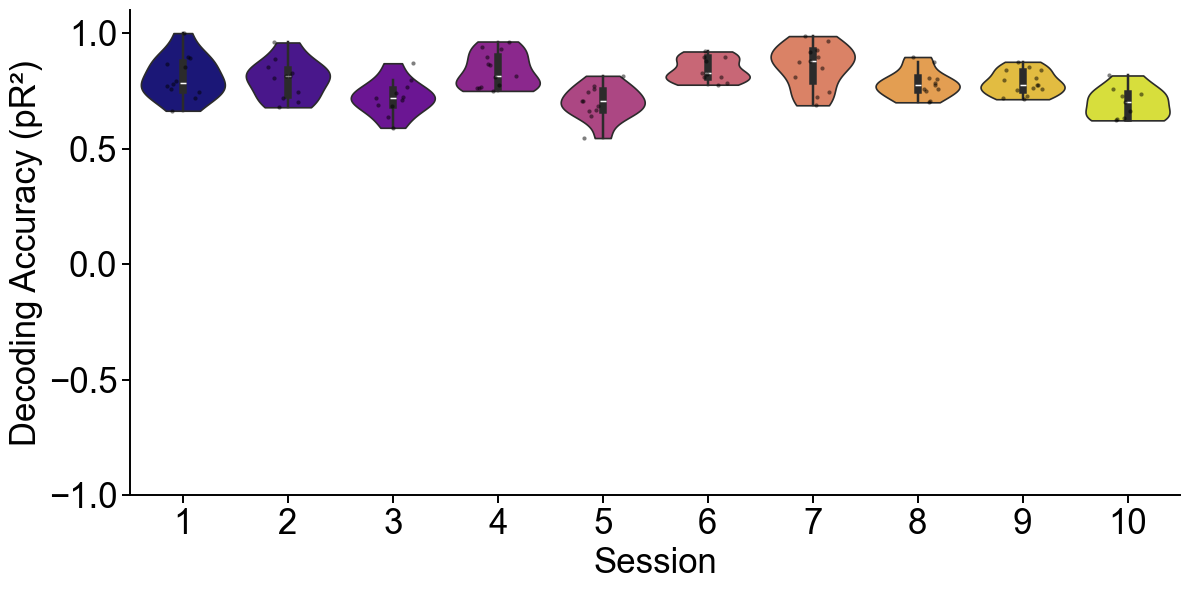

In [19]:
from functions_experimental_data_Bräckleinexp.GLM_analysis_force_pred import *

# === Input parameters ===
folder_path = '/Users/nmt121/Desktop/DATA/S7/'
bin_size_ms = 200  
session_files = session_files7

#regularization 
alpha_grid = {'poissonregressor__alpha': [0.1, 1, 10, 100, 1000]}  
session_results = {}

#init cross val
outer_kf = KFold(n_splits=10, shuffle=True, random_state=42)


def preprocess_trial_force(file, folder_path, bin_size_ms, fsamp=2048):
    file_path = os.path.join(folder_path, file)
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    force = np.array(data['Force'])
    if force.ndim == 2:
        force = force.squeeze()
        
    data_MU = np.array(data['MU'].tolist())

    # Convert bin size from ms to samples
    bin_size_samples = int(bin_size_ms * fsamp / 1000)

    # Determine number of bins
    num_timepoints = force.shape[0]
    num_bins = num_timepoints // bin_size_samples

    # Bin the spikes and force
    binned_spikes = np.add.reduceat(data_MU, np.arange(0, num_bins * bin_size_samples, bin_size_samples), axis=1)
    binned_force = np.add.reduceat(force[:num_bins * bin_size_samples], np.arange(0, num_bins * bin_size_samples, bin_size_samples)) / bin_size_samples

    mnpair = data['Idx_MU_Pair'].tolist()

    return binned_spikes, binned_force, mnpair


# === MAIN EXECUTION ===
session_results = {}

for session, pkl_files in session_files.items():
    session_pR2 = []
    force_trials = []
    spike_trials = []

    for file in pkl_files:
        spikes, force, mnpair = preprocess_trial_force(file,folder_path, bin_size_ms)
        if spikes is None or force is None:
            continue
        force_trials.append(force)
        spike_trials.append(spikes)

    if not force_trials or not spike_trials:
        continue

    concatenated_force = np.concatenate(force_trials)
    concatenated_spikes = np.hstack(spike_trials)
    num_neurons = concatenated_spikes.shape[0]

    for neuron_idx in range(num_neurons):
        
        if neuron_idx: #== mnpair[0] : #or target_idx == mnpair[1]:

            neuron_spikes = concatenated_spikes[neuron_idx, :]

            X, Y = create_force_glm_data(concatenated_force, neuron_spikes)
            if X is None or Y is None or np.sum(Y) < 20:
                continue

            # === Inner CV for alpha ===
            pipeline = make_pipeline(StandardScaler(), PoissonRegressor(max_iter=1000))
            inner_kf = KFold(n_splits=3, shuffle=True, random_state=42)
            poisson_cv = GridSearchCV(pipeline, alpha_grid, cv=inner_kf, scoring='neg_mean_poisson_deviance')
            poisson_cv.fit(X, Y)
            best_alpha = poisson_cv.best_params_['poissonregressor__alpha']

            # === Outer CV for model performance ===
            fold_pR2s = []
            for train_idx, test_idx in outer_kf.split(X):
                X_train, X_test = X[train_idx], X[test_idx]
                Y_train, Y_test = Y[train_idx], Y[test_idx]

                if np.sum(Y_test) < 5:
                    continue

                scaler = StandardScaler()
                X_train_scaled = scaler.fit_transform(X_train)
                X_test_scaled = scaler.transform(X_test)

                model = PoissonRegressor(alpha=best_alpha, max_iter=1000)
                model.fit(X_train_scaled, Y_train)

                pR2 = compute_pR2(model, X_test_scaled, Y_test)
                fold_pR2s.append(pR2)

            if fold_pR2s:
                mean_pR2 = np.nanmean(fold_pR2s)
                session_pR2.append(mean_pR2)

    if session_pR2:
        session_results[session] = session_pR2

# # === PLOTTING RESULTS ===

plt.figure(figsize=(12, 6))
plt.rcParams.update({'font.family': 'Arial'})

# === Prepare data for seaborn ===
all_pR2s = []
all_labels = []

for session, pR2_values in session_results.items():
    match = re.search(r'(\d+)', session)
    short_label = str(int(match.group(1))) if match else session
    all_pR2s.extend(pR2_values)
    all_labels.extend([short_label] * len(pR2_values))

# === Sort session labels numerically ===
unique_labels = sorted(set(all_labels), key=lambda x: int(x))
N = len(unique_labels)

cmap = plt.get_cmap('plasma')
colors = [cmap(i / (N - 1)) for i in range(N)]
palette_dict = dict(zip(unique_labels, colors))

# === Violin plot ===
sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2,palette=palette_dict, cut=0)
sns.stripplot(x=all_labels, y=all_pR2s, color='k', size=3, jitter=0.2, alpha=0.5)

# === Style settings ===
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(1.4)

plt.tick_params(width=1.4, length=6, labelsize=25)
plt.xlabel("Session", fontsize=25, fontname="Arial")
plt.ylabel("Decoding Accuracy (pR²)", fontsize=25, fontname="Arial")

# Make sure x-ticks are simplified numeric labels
ax.set_xticklabels(unique_labels, fontsize=25)

plt.ylim([-1, 1.1])
sns.despine(top=True, right=True)
plt.tight_layout()

# === Save ===
plt.savefig('/Users/nmt121/Desktop/Figures/GLM/GLM_Experimental_force_S7.pdf', dpi=300, bbox_inches='tight')
plt.show()

